# 14 — Day-30 Activity Groups: Does Grouping Activity Codes Help?

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Hank Butler's recommendation was: *"Engineer Features: Bin activity codes into simplified categories to improve feature
quality."*

The day-30 models in notebooks 10–12 use 15 individual activity codes as 0/1 features. The log has 398 different codes,
so most codes are left out. This notebook tests whether **grouping the codes into a small number of categories** helps
the day-30 Logistic Regression.

Everything else stays the same as notebooks 10–12:

- **Historically completed cases:** `case:endDate` is present.
- **Recorded activity span:** last event minus first event, in days (not a verified completion time).
- **Target:** `long_case = 1` if the span is more than 63 days (the exploratory threshold from `01_EDA.ipynb`).
- **Eligible at day 30:** the last recorded event is after first event + 30 days (a retrospective rule).
- **Splits:** the random split (677 / 161 cases) and the temporal split (617 / 168 cases) from notebooks 10–12.
- **Model:** `StandardScaler` + `LogisticRegression(max_iter=1000)`, default threshold, no tuning.

## 2. Load the Data and Build the Day-30 Cohort

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)
case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data["long_case"] = (case_data["duration_days"] > 63).astype(int)

case_data["prediction_time"] = case_data["first_event"] + pd.Timedelta(days=30)
active = case_data[case_data["last_event"] > case_data["prediction_time"]]

print("Completed cases:", len(case_data))
print("Day-30 eligible cases:", len(active))

Completed cases: 956
Day-30 eligible cases: 838


## 3. Activity Groups

`concept:name` holds the **activity code**: the type of administrative step, for example `01_HOOFD_010` =
"register submission date request". It is not a person; people are in `org:resource`.

Every code starts with a **prefix** such as `01_HOOFD` or `02_DRZ`. The group rule uses **only the code text**:

- the group is the prefix: `02_DRZ_010` → `02_DRZ`;
- `01_HOOFD` contains most of the codes, so for it I also keep the **first digit** of the number:
  `01_HOOFD_065_1` → `01_HOOFD_0xx`, `01_HOOFD_210` → `01_HOOFD_2xx`.

I do not know the official meaning of the prefixes, so I only describe each group by its codes and example English names.

In [3]:
def add_activity_groups(events):
    # the group is the prefix of the activity code, e.g. "02_DRZ" from "02_DRZ_010"
    events = events.copy()
    events["activity_group"] = events["concept:name"].str.extract(r"^(\d{2}_[A-Z0-9]+)_")[0]

    # for the main process 01_HOOFD, add the first digit of the number: "01_HOOFD_065_1" -> "01_HOOFD_0xx"
    is_main = events["activity_group"] == "01_HOOFD"
    first_digit = events.loc[is_main, "concept:name"].str[9]   # "01_HOOFD_" has 9 characters
    events.loc[is_main, "activity_group"] = "01_HOOFD_" + first_digit + "xx"
    return events


grouped_log = add_activity_groups(df)
print("Activity codes:", grouped_log["concept:name"].nunique())
print("Activity groups:", grouped_log["activity_group"].nunique())
print("Events without a group:", grouped_log["activity_group"].isna().sum())

Activity codes: 398
Activity groups: 28
Events without a group: 0


The table describes all groups in the whole log. It is only a description: it is **not** used to choose features.

In [4]:
rows = []
for group, events in grouped_log.groupby("activity_group"):
    examples = events["activityNameEN"].value_counts().head(2).index.tolist()
    rows.append({
        "group": group,
        "activity codes": events["concept:name"].nunique(),
        "events": len(events),
        "example English names": "; ".join(examples),
    })

group_table = pd.DataFrame(rows)
group_table

,group,activity codes,events,example English names
0,01_BB,25,502,set phase: phase permitting irrevocable; objec...
1,01_HOOFD_0xx,17,10723,send confirmation receipt; register submission...
2,01_HOOFD_1xx,26,6661,procedure change; registration date publication
3,01_HOOFD_2xx,13,3262,send letter in progress; treat subcases content
4,01_HOOFD_3xx,10,3563,phase advice known; grounds for refusal
5,01_HOOFD_4xx,44,8534,creating environmental permit decision; genera...
6,01_HOOFD_5xx,23,6103,enter senddate decision environmental permit; ...
7,01_HOOFD_6xx,2,2,enter senddate continuation; send continuation...
8,01_HOOFD_7xx,1,64,register deadline; close case
9,01_HOOFD_8xx,10,812,read publication date field; close case


## 4. Events Up to Day 30 and the Seven Count Features (Same as Notebooks 10–12)

**Keep only the events up to the cutoff.** For each case, keep its events timestamped on or before its own
`prediction_time`, and add `day` = days since the case's first event. Then add the activity group of each kept event.

In [5]:
def events_by_day30(event_table, cases):
    # keep only events of the given cases that happened on or before that case's day-30 cutoff
    events = event_table[event_table["case:concept:name"].isin(cases.index)].copy()
    events["prediction_time"] = events["case:concept:name"].map(cases["prediction_time"])
    events["first_event"] = events["case:concept:name"].map(cases["first_event"])
    first30 = events[events["time:timestamp"] <= events["prediction_time"]].copy()
    first30["day"] = (first30["time:timestamp"] - first30["first_event"]).dt.total_seconds() / (24 * 60 * 60)
    return first30

**The seven count features**, with exactly the same code as notebooks 10–12. Two of them are exact combinations of
others (repeated activities and events in days 16–30); they are kept for continuity.

In [6]:
count_columns = [
    "events_first30",
    "unique_activities_first30",
    "unique_resources_first30",
    "repeated_activities_first30",
    "events_first15",
    "events_days16_30",
    "days_since_last_event",
]


def count_features(first30, cases):
    first30 = first30.copy()
    first30["in_first15"] = first30["day"] <= 15
    features = first30.groupby("case:concept:name").agg(
        events_first30=("concept:name", "size"),
        unique_activities_first30=("concept:name", "nunique"),
        unique_resources_first30=("org:resource", "nunique"),
        events_first15=("in_first15", "sum"),
        last_event_by_day30=("time:timestamp", "max"),
    )
    features["repeated_activities_first30"] = features["events_first30"] - features["unique_activities_first30"]
    features["events_days16_30"] = features["events_first30"] - features["events_first15"]
    features["days_since_last_event"] = (
        cases.loc[features.index, "prediction_time"] - features["last_event_by_day30"]
    ).dt.total_seconds() / (24 * 60 * 60)
    return features[count_columns]

**Apply the helpers** to all eligible cases and check that no event after the cutoff was used.

In [7]:
first30 = add_activity_groups(events_by_day30(df, active))
counts = count_features(first30, active)
y = active.loc[counts.index, "long_case"]

print("Events recorded by day 30:", len(first30))
print("Latest event used, in days after the case start:", first30["day"].max())
print("Every event used is on or before its case's cutoff:", (first30["time:timestamp"] <= first30["prediction_time"]).all())
print("Activity groups recorded by day 30:", first30["activity_group"].nunique())

Events recorded by day 30: 14551
Latest event used, in days after the case start: 30.0
Every event used is on or before its case's cutoff: True
Activity groups recorded by day 30: 23


## 5. Feature Helpers

**The original activity indicators (same as notebooks 10–12).** `select_activities` returns the codes recorded in
10–90% of the given cases (at most 15, most frequent first, ties by code). It is only ever called with training cases.

In [8]:
def select_activities(first30, case_ids):
    # activity codes recorded in 10-90% of the given cases, at most 15, most frequent first (ties by code)
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("concept:name")["case:concept:name"].nunique() / len(case_ids) * 100
    share = share.rename("train_cases_pct").reset_index()
    share = share[(share["train_cases_pct"] >= 10) & (share["train_cases_pct"] <= 90)]
    share = share.sort_values(["train_cases_pct", "concept:name"], ascending=[False, True])
    return share.head(15)["concept:name"].tolist()


def activity_flags(first30, activities, case_ids):
    # 1 if the activity was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for activity in activities:
        cases_with_activity = first30.loc[first30["concept:name"] == activity, "case:concept:name"].unique()
        flags["act_" + activity] = flags.index.isin(cases_with_activity).astype(int)
    return flags

**Choose the activity groups using training cases only.** A group is kept if it was recorded by day 30 in at least
5% of the given cases. `01_HOOFD_0xx` is left out, because almost every case has it.

In [9]:
def select_groups(first30, case_ids):
    # activity groups recorded by day 30 in at least 5% of the given cases, except 01_HOOFD_0xx
    events = first30[first30["case:concept:name"].isin(case_ids)]
    share = events.groupby("activity_group")["case:concept:name"].nunique() / len(case_ids) * 100
    groups = share[share >= 5].index.tolist()
    groups.remove("01_HOOFD_0xx")
    return sorted(groups)

**Turn the groups into 0/1 columns.** One column per selected group (1 = the group was recorded by day 30), plus
`grp_other_group` for all remaining rare groups. `01_HOOFD_0xx` is not used at all.

In [10]:
def group_flags(first30, groups, case_ids):
    # 1 if the group was recorded by day 30 in that case, otherwise 0
    flags = pd.DataFrame(index=case_ids)
    for group in groups:
        cases_with_group = first30.loc[first30["activity_group"] == group, "case:concept:name"].unique()
        flags["grp_" + group] = flags.index.isin(cases_with_group).astype(int)

    # every rare group (not selected and not 01_HOOFD_0xx) goes into one column
    rare_events = first30[~first30["activity_group"].isin(groups + ["01_HOOFD_0xx"])]
    flags["grp_other_group"] = flags.index.isin(rare_events["case:concept:name"].unique()).astype(int)
    return flags

**The progress feature.** `highest_main_stage` is the highest `01_HOOFD` digit recorded by day 30 (0–8), so it says how
far a case had moved through the `01_HOOFD` codes. A case without any `01_HOOFD` event by day 30 gets 0.

In [11]:
def highest_main_stage(first30, case_ids):
    # highest first digit of a 01_HOOFD code recorded by day 30, e.g. 4 for "01_HOOFD_4xx"
    main_events = first30[first30["activity_group"].str.startswith("01_HOOFD_")]
    stages = main_events["activity_group"].str[9].astype(int)
    highest = stages.groupby(main_events["case:concept:name"]).max()
    return highest.reindex(case_ids).fillna(0).astype(int).rename("highest_main_stage")

**Build the feature table** for a list of cases and one of the three approaches:

- **A. Original:** 7 counts + the 15 selected activity indicators (exactly as in notebooks 10–12).
- **B. Grouped:** 7 counts + the selected group indicators + `grp_other_group` + `highest_main_stage`.
- **C. Combined:** everything from A and B.

In [12]:
def make_X(case_ids, approach, activities, groups):
    X = counts.loc[case_ids]
    if approach in ["A. Original", "C. Combined"]:
        X = X.join(activity_flags(first30, activities, case_ids))
    if approach in ["B. Grouped", "C. Combined"]:
        X = X.join(group_flags(first30, groups, case_ids))
        X = X.join(highest_main_stage(first30, case_ids))
    return X


approaches = ["A. Original", "B. Grouped", "C. Combined"]

**Fit and score.** Every approach uses the same Logistic Regression pipeline, so the scaler is fitted on the training
cases only. Precision and recall use the 0/1 predictions (threshold 0.5); ROC-AUC uses the predicted probabilities.

In [13]:
def fit_logistic_regression(X_train, y_train):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)


def score(model, X, y_true):
    predictions = model.predict(X)
    return {
        "ROC-AUC": roc_auc_score(y_true, model.predict_proba(X)[:, 1]),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions),
        "Cases flagged long": int(predictions.sum()),
    }

## 6. The Two Splits (Same as Notebooks 10–12)

**Random split:** the original split from notebook 07, filtered to day-30 cases (never redrawn).

In [14]:
day14_cases = case_data[case_data["last_event"] > case_data["first_event"] + pd.Timedelta(days=14)]
original_train_ids, original_test_ids = train_test_split(
    day14_cases.index, test_size=0.20, random_state=42, stratify=day14_cases["long_case"]
)

random_train_ids = [case for case in original_train_ids if case in active.index]
random_test_ids = [case for case in original_test_ids if case in active.index]

print("Random training cases:", len(random_train_ids), "| long:", y.loc[random_train_ids].sum())
print("Random test cases:", len(random_test_ids), "| long:", y.loc[random_test_ids].sum())
print("Overlap:", len(set(random_train_ids) & set(random_test_ids)))

Random training cases: 677 | long: 377
Random test cases: 161 | long: 95
Overlap: 0


**Temporal split:** train on older cases, test on the newest 20% (same rules as notebooks 11 and 12).

In [15]:
sorted_cases = active.sort_values("prediction_time", kind="stable")
boundary = sorted_cases["prediction_time"].iloc[int(len(sorted_cases) * 0.8)]

temporal_test = sorted_cases[sorted_cases["prediction_time"] >= boundary]
candidates = sorted_cases[sorted_cases["prediction_time"] < boundary]
temporal_train = candidates[(candidates["last_event"] < boundary) & (candidates["end_date"] < boundary)]
temporal_train_ids, temporal_test_ids = temporal_train.index, temporal_test.index

print("Boundary:", boundary)
print("Temporal training cases:", len(temporal_train_ids), "| long:", y.loc[temporal_train_ids].sum())
print("Temporal test cases:", len(temporal_test_ids), "| long:", y.loc[temporal_test_ids].sum())
print("Overlap:", len(set(temporal_train_ids) & set(temporal_test_ids)))

Boundary: 2013-10-25 22:00:00+00:00
Temporal training cases: 617 | long: 328
Temporal test cases: 168 | long: 100
Overlap: 0


## 7. Which Groups Are Selected?

On all random training cases (the same rule is repeated inside every cross-validation fold below):

In [16]:
random_groups = select_groups(first30, random_train_ids)
train_events = first30[first30["case:concept:name"].isin(random_train_ids)]
share = train_events.groupby("activity_group")["case:concept:name"].nunique() / len(random_train_ids) * 100

print("Selected groups:", len(random_groups))
print(random_groups)
print()
print("Share of random training cases with each group by day 30 (%):")
share.sort_values(ascending=False).round(1)

Selected groups: 16
['01_HOOFD_1xx', '01_HOOFD_2xx', '01_HOOFD_3xx', '01_HOOFD_4xx', '01_HOOFD_5xx', '02_DRZ', '03_GBH', '04_BPT', '05_EIND', '06_VD', '08_AWB45', '09_AH', '09_AWB45', '11_AH', '13_CRD', '14_VRIJ']

Share of random training cases with each group by day 30 (%):


activity_group
01_HOOFD_0xx    99.3
01_HOOFD_1xx    85.2
02_DRZ          63.1
04_BPT          62.9
01_HOOFD_2xx    24.4
08_AWB45        22.6
01_HOOFD_3xx    21.9
09_AH           21.4
01_HOOFD_4xx    20.2
05_EIND         19.6
11_AH           15.5
01_HOOFD_5xx    12.7
03_GBH           9.0
13_CRD           7.5
14_VRIJ          7.1
06_VD            6.4
09_AWB45         5.8
07_OPS           2.5
15_NGV           0.7
10_UOV           0.4
01_HOOFD_8xx     0.4
01_BB            0.3
03_VD            0.1
Name: case:concept:name, dtype: float64

## 8. Decision Rule (Fixed Before Looking at the Test Sets)

I prefer the approach with the **highest mean cross-validation ROC-AUC** on the random training cases. The random and
temporal test results are reported for all three approaches, but they are not used to choose.

## 9. Cross-Validation on the Random Training Cases

Same folds as notebooks 10 and 12: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`. In every fold, the
activities **and** the groups are selected on that fold's training part only.

In [17]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index = pd.Index(random_train_ids)   # lets us turn fold positions into case IDs

cv_rows = []
groups_per_fold = {}
for fold, (fit_positions, val_positions) in enumerate(folds.split(train_index, y.loc[train_index]), start=1):
    fit_ids = train_index[fit_positions]
    val_ids = train_index[val_positions]

    # selection uses the fold's training part only
    activities = select_activities(first30, fit_ids)
    groups = select_groups(first30, fit_ids)
    groups_per_fold[fold] = groups

    baseline = DummyClassifier(strategy="most_frequent").fit(counts.loc[fit_ids], y.loc[fit_ids])
    cv_rows.append({"Fold": fold, "Approach": "Majority baseline", **score(baseline, counts.loc[val_ids], y.loc[val_ids])})

    for approach in approaches:
        X_fit = make_X(fit_ids, approach, activities, groups)
        X_val = make_X(val_ids, approach, activities, groups)
        model = fit_logistic_regression(X_fit, y.loc[fit_ids])
        cv_rows.append({"Fold": fold, "Approach": approach, **score(model, X_val, y.loc[val_ids])})

cv_results = pd.DataFrame(cv_rows)
print("Number of groups selected in each fold:", {fold: len(groups) for fold, groups in groups_per_fold.items()})

Number of groups selected in each fold: {1: 16, 2: 16, 3: 16, 4: 16, 5: 16}


**Cross-validation results.** The standard deviation shows how much the five folds differ; it is not a confidence interval.

In [18]:
cv_summary = cv_results.groupby("Approach")[["ROC-AUC", "Precision", "Recall"]].agg(["mean", "std"])
cv_summary.round(3)

ROC-AUC        Precision        Recall       
                     mean    std      mean    std   mean    std
Approach                                                       
A. Original         0.702  0.033     0.668  0.026  0.719  0.036
B. Grouped          0.694  0.034     0.659  0.021  0.700  0.030
C. Combined         0.710  0.017     0.688  0.022  0.700  0.026
Majority baseline   0.500  0.000     0.557  0.002  1.000  0.000

In [19]:
cv_results.pivot(index="Fold", columns="Approach", values="ROC-AUC").round(3)

Approach,A. Original,B. Grouped,C. Combined,Majority baseline
Fold,,,,
1,0.755,0.716,0.736,0.5
2,0.667,0.667,0.696,0.5
3,0.707,0.739,0.708,0.5
4,0.683,0.658,0.696,0.5
5,0.698,0.692,0.714,0.5


In [20]:
cv_roc = cv_results[cv_results["Approach"] != "Majority baseline"].groupby("Approach")["ROC-AUC"].mean()
preferred = cv_roc.idxmax()
print("Mean cross-validation ROC-AUC:", cv_roc.round(3).to_dict())
print("Preferred approach (highest mean cross-validation ROC-AUC):", preferred)

Mean cross-validation ROC-AUC: {'A. Original': 0.702, 'B. Grouped': 0.694, 'C. Combined': 0.71}
Preferred approach (highest mean cross-validation ROC-AUC): C. Combined


## 10. Random Test and Temporal Test

Each approach is fitted once on the training cases of a split (with activities and groups selected on those training
cases) and scored once on that split's test cases.

In [21]:
def evaluate_split(train_ids, test_ids):
    activities = select_activities(first30, train_ids)
    groups = select_groups(first30, train_ids)
    results = {}

    baseline = DummyClassifier(strategy="most_frequent").fit(counts.loc[train_ids], y.loc[train_ids])
    results["Majority baseline"] = score(baseline, counts.loc[test_ids], y.loc[test_ids])

    for approach in approaches:
        X_train = make_X(train_ids, approach, activities, groups)
        X_test = make_X(test_ids, approach, activities, groups)
        model = fit_logistic_regression(X_train, y.loc[train_ids])
        results[approach] = score(model, X_test, y.loc[test_ids])
    return pd.DataFrame(results).T

In [22]:
random_results = evaluate_split(random_train_ids, random_test_ids)
temporal_results = evaluate_split(temporal_train_ids, temporal_test_ids)

print("Groups selected on the temporal training cases:", select_groups(first30, temporal_train_ids))

Groups selected on the temporal training cases: ['01_HOOFD_1xx', '01_HOOFD_2xx', '01_HOOFD_3xx', '01_HOOFD_4xx', '01_HOOFD_5xx', '02_DRZ', '03_GBH', '04_BPT', '05_EIND', '06_VD', '08_AWB45', '09_AH', '09_AWB45', '11_AH', '14_VRIJ']


## 11. Check: Approach A Reproduces Notebooks 10–12

Approach A uses exactly the same features and model as the Logistic Regression in notebooks 10–12. Its results must
match the outputs recorded there (rounded to 3 decimals); otherwise the comparison would not be fair.

In [23]:
recorded = {
    "cross-validation mean ROC-AUC": 0.702,
    "random test ROC-AUC": 0.659,
    "random test precision": 0.694,
    "random test recall": 0.716,
    "temporal test ROC-AUC": 0.678,
    "temporal test precision": 0.775,
    "temporal test recall": 0.550,
}
current = {
    "cross-validation mean ROC-AUC": cv_roc["A. Original"],
    "random test ROC-AUC": random_results.loc["A. Original", "ROC-AUC"],
    "random test precision": random_results.loc["A. Original", "Precision"],
    "random test recall": random_results.loc["A. Original", "Recall"],
    "temporal test ROC-AUC": temporal_results.loc["A. Original", "ROC-AUC"],
    "temporal test precision": temporal_results.loc["A. Original", "Precision"],
    "temporal test recall": temporal_results.loc["A. Original", "Recall"],
}

all_match = True
for name in recorded:
    match = abs(round(current[name], 3) - recorded[name]) < 0.0011
    all_match = all_match and match
    print(f"{name:<32} recorded {recorded[name]:.3f} | now {current[name]:.3f} | matches: {match}")
print("Flagged cases A (random / temporal):", int(random_results.loc["A. Original", "Cases flagged long"]),
      "/", int(temporal_results.loc["A. Original", "Cases flagged long"]))
assert all_match, "Approach A does not reproduce notebooks 10-12"

cross-validation mean ROC-AUC    recorded 0.702 | now 0.702 | matches: True
random test ROC-AUC              recorded 0.659 | now 0.659 | matches: True
random test precision            recorded 0.694 | now 0.694 | matches: True
random test recall               recorded 0.716 | now 0.716 | matches: True
temporal test ROC-AUC            recorded 0.678 | now 0.678 | matches: True
temporal test precision          recorded 0.775 | now 0.775 | matches: True
temporal test recall             recorded 0.550 | now 0.550 | matches: True
Flagged cases A (random / temporal): 98 / 71


## 12. Comparison Table

In [24]:
comparison = pd.DataFrame({
    "CV ROC-AUC mean": cv_results.groupby("Approach")["ROC-AUC"].mean(),
    "CV ROC-AUC std": cv_results.groupby("Approach")["ROC-AUC"].std(),
    "Random ROC-AUC": random_results["ROC-AUC"],
    "Random precision": random_results["Precision"],
    "Random recall": random_results["Recall"],
    "Random flagged (of 161)": random_results["Cases flagged long"],
    "Temporal ROC-AUC": temporal_results["ROC-AUC"],
    "Temporal precision": temporal_results["Precision"],
    "Temporal recall": temporal_results["Recall"],
    "Temporal flagged (of 168)": temporal_results["Cases flagged long"],
}).astype(float)

comparison = comparison.loc[["Majority baseline"] + approaches]
comparison["Random flagged (of 161)"] = comparison["Random flagged (of 161)"].astype(int)
comparison["Temporal flagged (of 168)"] = comparison["Temporal flagged (of 168)"].astype(int)
comparison.round(3)

,CV ROC-AUC mean,CV ROC-AUC std,Random ROC-AUC,Random precision,Random recall,Random flagged (of 161),Temporal ROC-AUC,Temporal precision,Temporal recall,Temporal flagged (of 168)
Majority baseline,0.500,0.000,0.500,0.590,1.000,161,0.500,0.595,1.00,168
A. Original,0.702,0.033,0.659,0.694,0.716,98,0.678,0.775,0.55,71
B. Grouped,0.694,0.034,0.680,0.674,0.653,92,0.709,0.644,0.85,132
C. Combined,0.710,0.017,0.708,0.730,0.768,100,0.705,0.847,0.50,59


### ROC-AUC chart

The black error bars show **±1 standard deviation across the five folds** (not a confidence interval). The dashed line
is the majority baseline (0.50, no ranking).

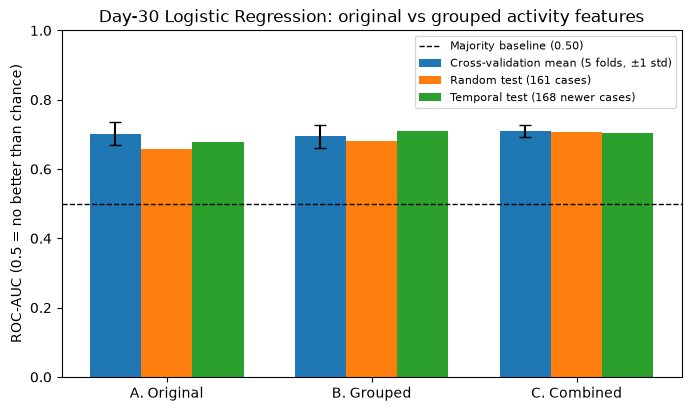

In [25]:
positions = [0, 1, 2]
width = 0.25

plt.figure(figsize=(8, 4.5))
plt.bar([p - width for p in positions], comparison.loc[approaches, "CV ROC-AUC mean"], width,
        yerr=comparison.loc[approaches, "CV ROC-AUC std"], capsize=4, label="Cross-validation mean (5 folds, ±1 std)")
plt.bar(positions, comparison.loc[approaches, "Random ROC-AUC"], width, label="Random test (161 cases)")
plt.bar([p + width for p in positions], comparison.loc[approaches, "Temporal ROC-AUC"], width,
        label="Temporal test (168 newer cases)")
plt.axhline(0.5, color="black", linestyle="--", linewidth=1, label="Majority baseline (0.50)")
plt.xticks(positions, ["A. Original", "B. Grouped", "C. Combined"])
plt.ylim(0, 1)
plt.ylabel("ROC-AUC (0.5 = no better than chance)")
plt.title("Day-30 Logistic Regression: original vs grouped activity features")
plt.legend(loc="upper right", fontsize=8)
plt.show()

## 13. Leakage Check

I change the activity and resource of **every event after each case's day-30 cutoff** to fake values, keep the cohort and
the cutoffs fixed, and rebuild all features of approach C (counts, activity indicators, group indicators and the progress
feature) with the same helpers. If the features only use events up to day 30, nothing may change.

In [26]:
check_activities = select_activities(first30, random_train_ids)
check_groups = select_groups(first30, random_train_ids)
all_ids = list(counts.index)

changed = df.copy()
after_day30 = changed["time:timestamp"] > changed["case:concept:name"].map(active["prediction_time"])
changed.loc[after_day30, "concept:name"] = "FAKE_ACTIVITY"
changed.loc[after_day30, "org:resource"] = "FAKE_RESOURCE"
changed_first30 = add_activity_groups(events_by_day30(changed, active))

In [27]:
original_features = make_X(all_ids, "C. Combined", check_activities, check_groups)

changed_counts = count_features(changed_first30, active).loc[all_ids]
changed_features = changed_counts.join(activity_flags(changed_first30, check_activities, all_ids))
changed_features = changed_features.join(group_flags(changed_first30, check_groups, all_ids))
changed_features = changed_features.join(highest_main_stage(changed_first30, all_ids))

print("Events changed:", after_day30.sum())
print("All features unchanged:", changed_features.equals(original_features))

Events changed: 26120
All features unchanged: True


**What this check shows, and what it does not.** There are three separate questions:

1. **Feature timing:** the features use only events timestamped on or before day 30. The check above tests this in code.
2. **Retrospective cohort selection:** a case is included only if its last recorded event is after day 30. That uses the
   last event, which is only known afterwards. The check does not change this.
3. **Real-world knowledge of open cases:** a live system would need to know which cases are really still open at day 30.
   This log does not show that reliably. The check does not change this either.

A successful leakage check therefore does **not** solve limitations 2 and 3.

## 14. Interpretation

**Grouping rule.** The 398 activity codes form 28 groups; 23 of them are recorded by day 30. On the random training
cases, 16 groups pass the 5% rule (every cross-validation fold also selected 16), and the remaining rare groups are
combined into `grp_other_group`.

**Approach A reproduces notebooks 10–12 exactly** (ROC-AUC 0.702 / 0.659 / 0.678), so the comparison is fair.

**Decision by cross-validation (fixed in advance).** The mean cross-validation ROC-AUC is 0.702 for A, 0.694 for B and
0.710 for C, so **C. Combined** is the preferred approach. B (groups instead of individual codes) is slightly lower than A.
The gain of C over A (0.008) is much smaller than the variation between folds (standard deviation 0.033 for A), so
cross-validation alone does not show a clear improvement. C was, however, more stable across the folds (standard
deviation 0.017, lowest fold 0.696).

**Test sets.** C also has a higher ROC-AUC than A on both test sets: 0.708 vs 0.659 on the random test and 0.705 vs
0.678 on the temporal test. B is between them (0.680 and 0.709).

**Warnings (precision and recall) are still unstable.**

- C on the random test flags 100 of 161 cases: precision 0.730, recall 0.768.
- C on the temporal test flags only 59 of 168 cases: precision 0.847, recall 0.50, so it misses half of the long cases.
- B changes even more between the tests: it flags 92 cases on the random test but 132 on the temporal test (recall 0.85).

**Answer.** Adding activity groups to the original features (C) gives a **small improvement in ranking**, seen in
cross-validation and on both test sets. Replacing the individual codes with groups (B) does not improve
cross-validation. The improvement is modest, the cross-validation gain is within the fold-to-fold variation, and the test
sets had already been used before, so this is **exploratory evidence**. The warning behaviour at the default threshold
still changes a lot between test sets, so the model is still **not ready for operational use**.

## 15. Limitations

- The random and temporal test cases were **already used** during exploratory modelling in notebooks 07–12, so these are
  **not** independent final validations. 138 of the 168 temporal test cases were training cases in the random split.
- The cohort is retrospective, and the 63-day threshold was chosen with all completed cases (`01_EDA.ipynb`).
- The meaning of each prefix is not documented in the sources I used, so the groups are described only by their codes
  and English names. Coefficients and groups are **not** causal explanations.
- Only Logistic Regression with fixed settings was tested; the 5% rule and the grouping rule were fixed in advance and
  not tuned.
- One Dutch municipality; not SPAR or Montenegro data.